Import libraries

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


# Create the complete traditional ML results table

In [12]:
traditional_results = [
    ["English", "TF-IDF", "Logistic Regression", 0.580, 0.5843],
    ["English", "TF-IDF", "Linear SVM", 0.565, 0.5594],
    ["English", "FastText", "Logistic Regression", 0.560, 0.5535],
    ["English", "FastText", "Linear SVM", 0.615, 0.6038],
    ["English", "Word2Vec", "Logistic Regression", 0.595, 0.5856],
    ["English", "Word2Vec", "Linear SVM", 0.595, 0.5811],

    ["Hindi", "TF-IDF", "Logistic Regression", 0.530, 0.5203],
    ["Hindi", "TF-IDF", "Linear SVM", 0.525, 0.5106],
    ["Hindi", "FastText", "Logistic Regression", 0.530, 0.5258],
    ["Hindi", "FastText", "Linear SVM", 0.590, 0.5703],
    ["Hindi", "Word2Vec", "Logistic Regression", 0.540, 0.5337],
    ["Hindi", "Word2Vec", "Linear SVM", 0.595, 0.5706],

    ["Bengali", "TF-IDF", "Logistic Regression", 0.565, 0.5421],
    ["Bengali", "TF-IDF", "Linear SVM", 0.555, 0.5237],
    ["Bengali", "FastText", "Logistic Regression", 0.605, 0.5947],
    ["Bengali", "FastText", "Linear SVM", 0.635, 0.6160],
    ["Bengali", "Word2Vec", "Logistic Regression", 0.570, 0.5612],
    ["Bengali", "Word2Vec", "Linear SVM", 0.590, 0.5735]
]

traditional_df = pd.DataFrame(
    traditional_results,
    columns=[
        "Language",
        "Feature",
        "Classifier",
        "Accuracy",
        "Macro F1"
    ]
)

print("Traditional ML Results")
display(traditional_df)

Traditional ML Results


,Language,Feature,Classifier,Accuracy,Macro F1
0,English,TF-IDF,Logistic Regression,0.580,0.5843
1,English,TF-IDF,Linear SVM,0.565,0.5594
2,English,FastText,Logistic Regression,0.560,0.5535
3,English,FastText,Linear SVM,0.615,0.6038
4,English,Word2Vec,Logistic Regression,0.595,0.5856
5,English,Word2Vec,Linear SVM,0.595,0.5811
6,Hindi,TF-IDF,Logistic Regression,0.530,0.5203
7,Hindi,TF-IDF,Linear SVM,0.525,0.5106
8,Hindi,FastText,Logistic Regression,0.530,0.5258
9,Hindi,FastText,Linear SVM,0.590,0.5703


Create the Transformer results table

In [13]:
transformer_results = [
    ["English", "XLM-R", "Original", 0.755, 0.7497],
    ["English", "IndicBERT v2", "Original", 0.735, 0.7250],

    ["Hindi", "XLM-R", "MarianMT", 0.605, 0.4471],
    ["Hindi", "IndicBERT v2", "MarianMT", 0.640, 0.5823],

    ["Bengali", "XLM-R", "MarianMT", 0.425, 0.1988],
    ["Bengali", "XLM-R", "NLLB-200", 0.425, 0.1988],
    ["Bengali", "IndicBERT v2", "MarianMT", 0.620, 0.5883]
]

transformer_df = pd.DataFrame(
    transformer_results,
    columns=[
        "Language",
        "Model",
        "Translation",
        "Accuracy",
        "Macro F1"
    ]
)

print("Transformer Results")
display(transformer_df)

Transformer Results


,Language,Model,Translation,Accuracy,Macro F1
0,English,XLM-R,Original,0.755,0.7497
1,English,IndicBERT v2,Original,0.735,0.7250
2,Hindi,XLM-R,MarianMT,0.605,0.4471
3,Hindi,IndicBERT v2,MarianMT,0.640,0.5823
4,Bengali,XLM-R,MarianMT,0.425,0.1988
5,Bengali,XLM-R,NLLB-200,0.425,0.1988
6,Bengali,IndicBERT v2,MarianMT,0.620,0.5883


# Combine all experimental results

In [14]:
traditional_master = traditional_df.copy()

traditional_master["Model Type"] = "Traditional ML"
traditional_master["Model"] = (
    traditional_master["Feature"] + " + " +
    traditional_master["Classifier"]
)

traditional_master["Details"] = traditional_master["Classifier"]

traditional_master = traditional_master[
    ["Language", "Model Type", "Model", "Accuracy", "Macro F1"]
]

transformer_master = transformer_df.copy()

transformer_master["Model Type"] = "Transformer"
transformer_master["Model"] = transformer_master["Model"]
transformer_master["Details"] = transformer_master["Translation"]

transformer_master = transformer_master[
    ["Language", "Model Type", "Model", "Accuracy", "Macro F1"]
]

master_df = pd.concat(
    [traditional_master, transformer_master],
    ignore_index=True
)

master_df = master_df.sort_values(
    by="Macro F1",
    ascending=False
).reset_index(drop=True)

print("MASTER EXPERIMENTAL RESULTS")
print("Total experiments:", len(master_df))

display(master_df)

MASTER EXPERIMENTAL RESULTS
Total experiments: 25


,Language,Model Type,Model,Accuracy,Macro F1
0,English,Transformer,XLM-R,0.755,0.7497
1,English,Transformer,IndicBERT v2,0.735,0.7250
2,Bengali,Traditional ML,FastText + Linear SVM,0.635,0.6160
3,English,Traditional ML,FastText + Linear SVM,0.615,0.6038
4,Bengali,Traditional ML,FastText + Logistic Regression,0.605,0.5947
5,Bengali,Transformer,IndicBERT v2,0.620,0.5883
6,English,Traditional ML,Word2Vec + Logistic Regression,0.595,0.5856
7,English,Traditional ML,TF-IDF + Logistic Regression,0.580,0.5843
8,Hindi,Transformer,IndicBERT v2,0.640,0.5823
9,English,Traditional ML,Word2Vec + Linear SVM,0.595,0.5811


# Identify the best model for each language

In [15]:
best_indices = master_df.groupby("Language")["Macro F1"].idxmax()

best_models = master_df.loc[best_indices].reset_index(drop=True)

best_models = best_models.sort_values(
    by="Macro F1",
    ascending=False
)

print("BEST MODEL FOR EACH LANGUAGE")
display(best_models)

BEST MODEL FOR EACH LANGUAGE


,Language,Model Type,Model,Accuracy,Macro F1
1,English,Transformer,XLM-R,0.755,0.7497
0,Bengali,Traditional ML,FastText + Linear SVM,0.635,0.6160
2,Hindi,Transformer,IndicBERT v2,0.640,0.5823


# Visualize the best model for each language

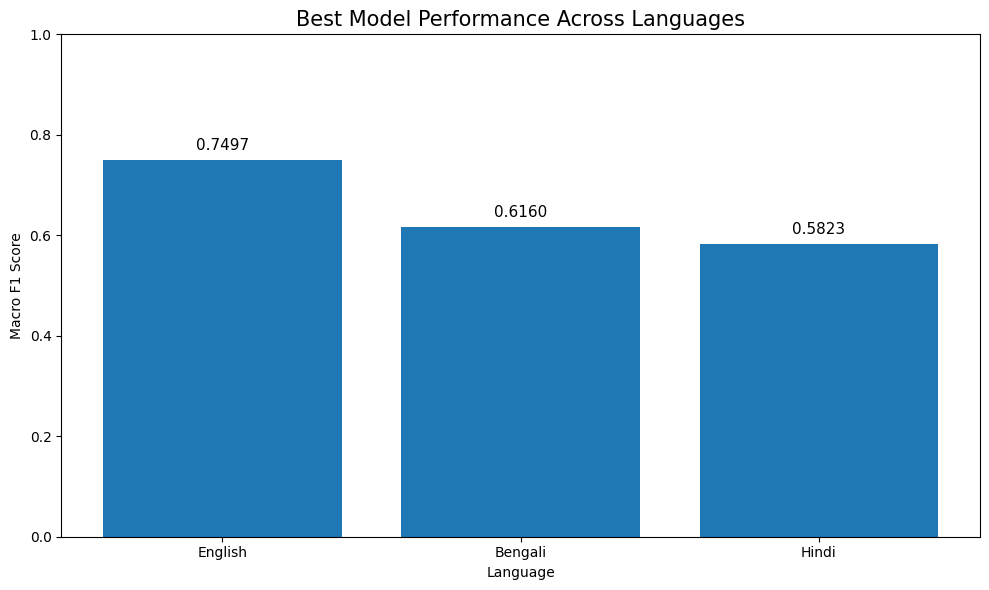

In [16]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    best_models["Language"],
    best_models["Macro F1"]
)

plt.title("Best Model Performance Across Languages",
          fontsize=15)

plt.xlabel("Language")
plt.ylabel("Macro F1 Score")

plt.ylim(0, 1)

for bar, (_, row) in zip(bars, best_models.iterrows()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f'{row["Macro F1"]:.4f}',
        ha="center",
        fontsize=11
    )

plt.tight_layout()
plt.show()

# Macro F1 comparison across all models

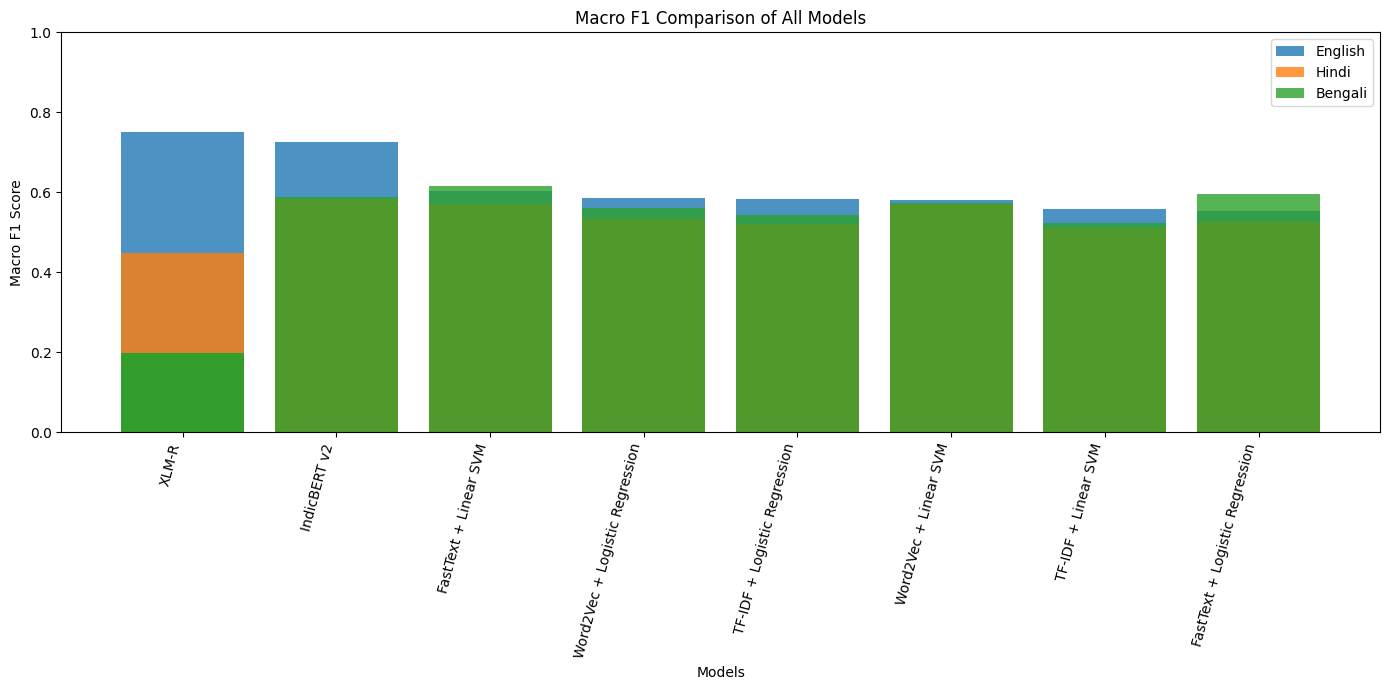

In [17]:
plt.figure(figsize=(14, 7))

for language in ["English", "Hindi", "Bengali"]:
    language_df = master_df[
        master_df["Language"] == language
    ]

    plt.bar(
        language_df["Model"],
        language_df["Macro F1"],
        label=language,
        alpha=0.8
    )

plt.title("Macro F1 Comparison of All Models")
plt.xlabel("Models")
plt.ylabel("Macro F1 Score")

plt.xticks(rotation=75, ha="right")
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

# Create an accuracy comparison chart

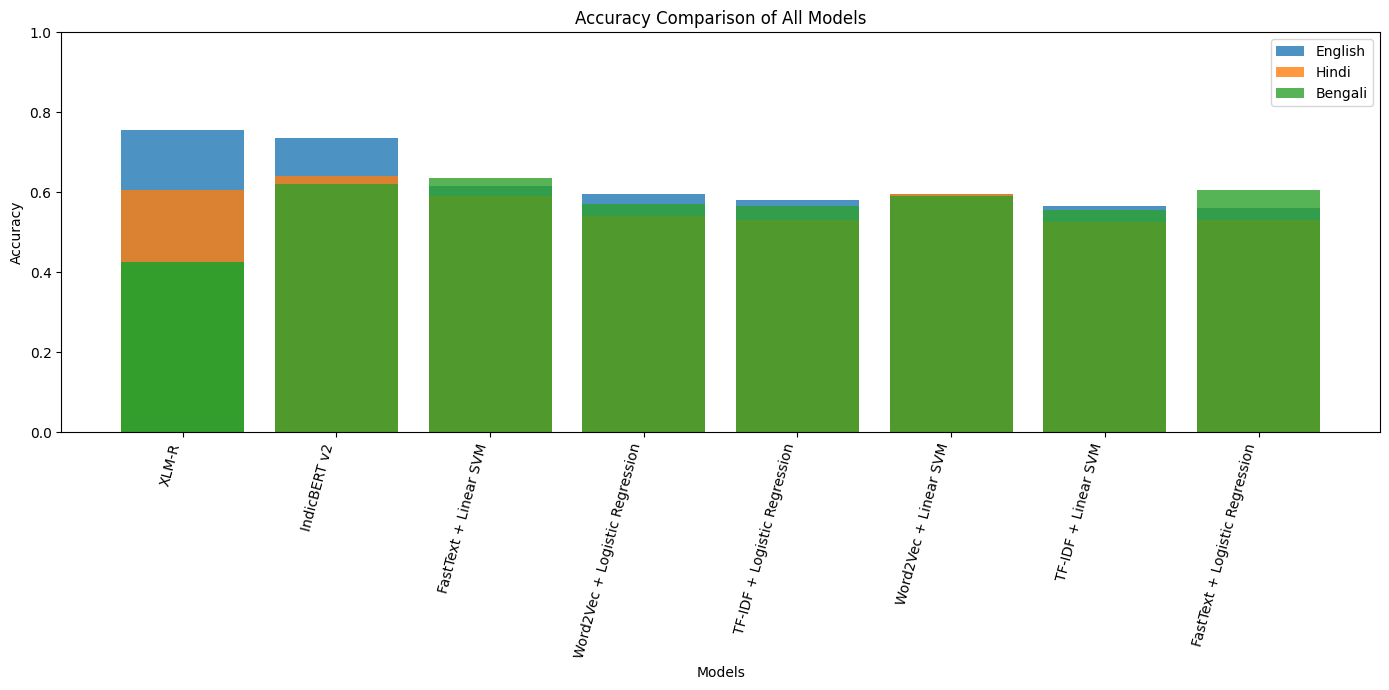

In [18]:
plt.figure(figsize=(14, 7))

for language in ["English", "Hindi", "Bengali"]:
    language_df = master_df[
        master_df["Language"] == language
    ]

    plt.bar(
        language_df["Model"],
        language_df["Accuracy"],
        label=language,
        alpha=0.8
    )

plt.title("Accuracy Comparison of All Models")
plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.xticks(rotation=75, ha="right")
plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

Save the final results

In [19]:
master_df.to_csv(
    "all_model_results.csv",
    index=False
)

best_models.to_csv(
    "best_models_by_language.csv",
    index=False
)

print("Files saved successfully!")
print("1. all_model_results.csv")
print("2. best_models_by_language.csv")

Files saved successfully!
1. all_model_results.csv
2. best_models_by_language.csv


# Prepare the final comparison summary

In [20]:
print("=" * 60)
print("FINAL MULTILINGUAL STANCE DETECTION SUMMARY")
print("=" * 60)

for _, row in best_models.iterrows():
    print(f"\nLanguage: {row['Language']}")
    print(f"Best Model: {row['Model']}")
    print(f"Model Type: {row['Model Type']}")
    print(f"Accuracy: {row['Accuracy']:.4f}")
    print(f"Macro F1: {row['Macro F1']:.4f}")

print("\n" + "=" * 60)
print("TOTAL EXPERIMENTS:", len(master_df))
print("LANGUAGES:", master_df["Language"].nunique())
print("TRADITIONAL ML EXPERIMENTS:",
      len(traditional_df))
print("TRANSFORMER EXPERIMENTS:",
      len(transformer_df))
print("=" * 60)

FINAL MULTILINGUAL STANCE DETECTION SUMMARY

Language: English
Best Model: XLM-R
Model Type: Transformer
Accuracy: 0.7550
Macro F1: 0.7497

Language: Bengali
Best Model: FastText + Linear SVM
Model Type: Traditional ML
Accuracy: 0.6350
Macro F1: 0.6160

Language: Hindi
Best Model: IndicBERT v2
Model Type: Transformer
Accuracy: 0.6400
Macro F1: 0.5823

TOTAL EXPERIMENTS: 25
LANGUAGES: 3
TRADITIONAL ML EXPERIMENTS: 18
TRANSFORMER EXPERIMENTS: 7


#  Results and Discussion

## 1 Overall Experimental Findings

A total of 25 experiments were conducted using traditional machine learning and transformer-based approaches across English, Hindi, and Bengali. The models were evaluated using Accuracy and Macro F1-score on the same held-out test set of 200 samples.

The experiments show that model performance varies across languages. No single model performed best for all three languages.

## 2 English Results

For English, XLM-RoBERTa achieved the best performance, with an accuracy of **75.5%** and a Macro F1-score of **74.97%**. IndicBERT v2 achieved an accuracy of 73.5% and a Macro F1-score of 72.50%.

These results suggest that XLM-RoBERTa was effective at capturing contextual information in English sentences, which is important for identifying stance.

## 3 Hindi Results

For Hindi, IndicBERT v2 achieved the best performance, with an accuracy of **64.0%** and a Macro F1-score of **58.23%**.

It performed better than XLM-RoBERTa, which achieved an accuracy of 60.5% and a Macro F1-score of 44.71%.

This result suggests that IndicBERT's pretraining on Indian languages may provide useful representations for Hindi stance detection.

## 4 Bengali Results

For Bengali, FastText combined with Linear SVM achieved the best performance, with an accuracy of **63.5%** and a Macro F1-score of **61.60%**.

IndicBERT v2 achieved an accuracy of 62.0% and a Macro F1-score of 58.83%.

XLM-RoBERTa performed poorly on Bengali, achieving an accuracy of 42.5% and a Macro F1-score of 19.88%. Its predictions were concentrated entirely in the Neutral class.

The results indicate that traditional machine learning with FastText embeddings was more effective than the tested transformer models for this Bengali dataset.

## 5 Comparative Discussion

The experimental results highlight three important observations:

1. **Language-dependent performance:** The best-performing model differed across English, Hindi, and Bengali.
2. **Effectiveness of Indic language pretraining:** IndicBERT v2 showed stronger results than XLM-RoBERTa for Hindi and Bengali in our experiments.
3. **Traditional machine learning remains useful:** FastText with Linear SVM achieved the best Bengali result, demonstrating that traditional approaches can remain competitive with transformer-based models.

The difference in performance may be related to language-specific characteristics, the size of the training dataset, translation quality, and the suitability of pretrained representations. These factors require further investigation.

## 6 Summary

Overall, XLM-RoBERTa was the strongest model for English, IndicBERT v2 was the strongest model for Hindi, and FastText with Linear SVM was the strongest model for Bengali.

These findings demonstrate that multilingual stance detection requires careful model selection for individual languages rather than relying on a single universal model.